# Imputación de PM10 y PM2.5 mediante Random Forest

**Estación:** PALMIRA  
**Periodo:** 2022-01-01 a 2022-12-31  
**Objetivo:** reconstruir los valores faltantes de PM10 y PM2.5 usando covariables meteorológicas y variables temporales.

Este notebook genera:

- revisión inicial de bases;
- tabla de faltantes antes de imputar;
- estadísticos descriptivos antes y después;
- gráficas de series originales y finales;
- entrenamiento/validación del modelo Random Forest;
- métricas de validación;
- valores imputados;
- importancia de variables;
- base final imputada.

In [43]:
# ==========================================
# 1. LIBRERÍAS
# ==========================================

import os
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [44]:
# ==========================================
# 2. CONFIGURACIÓN DE RUTAS
# ==========================================

# Guarda este notebook en la misma carpeta donde están los CSV.
DATA_DIR = Path(".")

ARCHIVOS = {
    "DViento": DATA_DIR / "DViento_dataset_completo_final.csv",
    "HAire10": DATA_DIR / "HAire10_dataset_completo_final.csv",
    "P": DATA_DIR / "P_dataset_completo_final.csv",
    "RGlobal": DATA_DIR / "RGlobal_dataset_completo_final.csv",
    "TMPR_AIR_10CM": DATA_DIR / "TMPR_AIR_10CM_dataset_completo_final.csv",
    "VViento": DATA_DIR / "VViento_dataset_completo_final.csv",
    "PM10": DATA_DIR / "PM10.csv",
    "PM25": DATA_DIR / "PM25.csv",
}

SALIDAS = Path("salidas_imputacion_RF_PM10_PM25_Palmira_2022")
TABLAS = SALIDAS / "tablas"
GRAFICAS = SALIDAS / "graficas"

TABLAS.mkdir(parents=True, exist_ok=True)
GRAFICAS.mkdir(parents=True, exist_ok=True)

for nombre, ruta in ARCHIVOS.items():
    print(f"{nombre:15s} -> {ruta} | Existe: {ruta.exists()}")

DViento         -> DViento_dataset_completo_final.csv | Existe: True
HAire10         -> HAire10_dataset_completo_final.csv | Existe: True
P               -> P_dataset_completo_final.csv | Existe: True
RGlobal         -> RGlobal_dataset_completo_final.csv | Existe: True
TMPR_AIR_10CM   -> TMPR_AIR_10CM_dataset_completo_final.csv | Existe: True
VViento         -> VViento_dataset_completo_final.csv | Existe: True
PM10            -> PM10.csv | Existe: True
PM25            -> PM25.csv | Existe: True


In [45]:
# ==========================================
# 3. FUNCIONES DE APOYO
# ==========================================

def leer_csv_robusto(ruta):
    '''
    Lee archivos CSV con diferentes separadores y codificaciones.
    '''
    ruta = Path(ruta)
    for enc in ["utf-8-sig", "utf-8", "latin1", "cp1252"]:
        for sep in [None, ";", ",", "\t", "|"]:
            try:
                df = pd.read_csv(
                    ruta,
                    sep=sep,
                    engine="python" if sep is None else "c",
                    encoding=enc
                )
                if df.shape[1] > 1:
                    return df
            except Exception:
                continue
    raise ValueError(f"No fue posible leer el archivo: {ruta}")


def normalizar_estacion(serie):
    '''
    Normaliza nombres de estaciones para evitar problemas por tildes, espacios o mayúsculas.
    '''
    return (
        serie.astype(str)
        .str.strip()
        .str.upper()
        .str.replace("Á", "A", regex=False)
        .str.replace("É", "E", regex=False)
        .str.replace("Í", "I", regex=False)
        .str.replace("Ó", "O", regex=False)
        .str.replace("Ú", "U", regex=False)
    )


def smape(y_true, y_pred):
    y_true = np.array(y_true, dtype=float)
    y_pred = np.array(y_pred, dtype=float)
    denom = (np.abs(y_true) + np.abs(y_pred)) / 2
    mask = denom != 0
    return np.mean(np.abs(y_true[mask] - y_pred[mask]) / denom[mask]) * 100


def mape_sin_ceros(y_true, y_pred):
    y_true = np.array(y_true, dtype=float)
    y_pred = np.array(y_pred, dtype=float)
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100


def estadisticos(serie):
    return {
        "n": int(serie.count()),
        "faltantes": int(serie.isna().sum()),
        "media": serie.mean(),
        "mediana": serie.median(),
        "desv_std": serie.std(),
        "min": serie.min(),
        "q25": serie.quantile(0.25),
        "q75": serie.quantile(0.75),
        "max": serie.max()
    }


def guardar_mostrar_figura(nombre):
    plt.tight_layout()
    ruta = GRAFICAS / nombre
    plt.savefig(ruta, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Gráfica guardada en: {ruta}")

In [46]:
# ==========================================
# 4. CARGA Y REVISIÓN INICIAL DE ARCHIVOS
# ==========================================

resumen_archivos = []

for nombre, ruta in ARCHIVOS.items():
    df_temp = leer_csv_robusto(ruta)
    resumen_archivos.append({
        "Archivo": nombre,
        "Filas": df_temp.shape[0],
        "Columnas": df_temp.shape[1],
        "Nombres_columnas": ", ".join(df_temp.columns.astype(str))
    })

resumen_archivos = pd.DataFrame(resumen_archivos)
display(resumen_archivos)

resumen_archivos.to_csv(TABLAS / "01_resumen_archivos_cargados.csv", index=False, encoding="utf-8-sig")

,Archivo,Filas,Columnas,Nombres_columnas
0,DViento,365,6,"Estacion, Fecha inicial, Fecha final, DViento,..."
1,HAire10,365,6,"Estacion, Fecha inicial, Fecha final, HAire10,..."
2,P,365,6,"Estacion, Fecha inicial, Fecha final, P, Fue_f..."
3,RGlobal,365,6,"Estacion, Fecha inicial, Fecha final, RGlobal,..."
4,TMPR_AIR_10CM,365,6,"Estacion, Fecha inicial, Fecha final, TMPR AIR..."
5,VViento,365,6,"Estacion, Fecha inicial, Fecha final, VViento,..."
6,PM10,3419,4,"Estacion, Fecha inicial, Fecha final, PM10"
7,PM25,3244,4,"Estacion, Fecha inicial, Fecha final, PM2.5"


In [47]:
# ==========================================
# 5. CARGA DE COVARIABLES METEOROLÓGICAS
# ==========================================

covariables = ["DViento", "HAire10", "P", "RGlobal", "TMPR_AIR_10CM", "VViento"]

bases_covariables = []

for variable in covariables:
    df = leer_csv_robusto(ARCHIVOS[variable])
    df.columns = [c.strip() for c in df.columns]
    df["Estacion"] = normalizar_estacion(df["Estacion"])
    df["Fecha inicial"] = pd.to_datetime(df["Fecha inicial"], errors="coerce")

    if variable == "TMPR_AIR_10CM":
        candidatos = [c for c in df.columns if "TMPR" in c.upper() and "10" in c.upper()]
        columna_valor = candidatos[0]
    else:
        columna_valor = variable

    df = df[df["Estacion"].eq("PALMIRA")].copy()
    df = df[["Estacion", "Fecha inicial", columna_valor]].rename(columns={columna_valor: variable})
    df = df.groupby(["Estacion", "Fecha inicial"], as_index=False)[variable].mean()

    bases_covariables.append(df)

from functools import reduce

base_cov = reduce(
    lambda izquierda, derecha: pd.merge(izquierda, derecha, on=["Estacion", "Fecha inicial"], how="outer"),
    bases_covariables
)

base_cov = base_cov.sort_values(["Estacion", "Fecha inicial"]).reset_index(drop=True)

display(Markdown("## Base de covariables"))
display(base_cov.head())
display(base_cov.tail())

revision_cov = pd.DataFrame({
    "Variable": covariables,
    "Faltantes": [base_cov[c].isna().sum() for c in covariables],
    "Mínimo": [base_cov[c].min() for c in covariables],
    "Máximo": [base_cov[c].max() for c in covariables],
    "Media": [base_cov[c].mean() for c in covariables],
})

display(revision_cov)

base_cov.to_csv(TABLAS / "02_base_covariables_Palmira_2022.csv", index=False, encoding="utf-8-sig")
revision_cov.to_csv(TABLAS / "03_revision_covariables.csv", index=False, encoding="utf-8-sig")

## Base de covariables

,Estacion,Fecha inicial,DViento,HAire10,P,RGlobal,TMPR_AIR_10CM,VViento
0,PALMIRA,2022-01-01,132.583333,84.366667,674.733333,81.258333,22.791667,1.245833
1,PALMIRA,2022-01-02,136.625000,74.720833,675.304167,126.820833,24.291667,1.300000
2,PALMIRA,2022-01-03,143.083333,86.337500,675.820833,98.195833,22.570833,0.933333
3,PALMIRA,2022-01-04,206.166667,77.820833,674.791667,128.458333,23.500000,1.316667
4,PALMIRA,2022-01-05,210.291667,79.095833,673.908333,106.945833,23.308333,1.287500


,Estacion,Fecha inicial,DViento,HAire10,P,RGlobal,TMPR_AIR_10CM,VViento
360,PALMIRA,2022-12-27,167.791667,78.766667,676.062500,123.587500,23.012500,1.283333
361,PALMIRA,2022-12-28,76.166667,84.050000,338.354167,50.545833,22.041667,0.558333
362,PALMIRA,2022-12-29,0.000000,79.933778,0.000000,0.000000,22.598753,0.000000
363,PALMIRA,2022-12-30,133.208333,63.315385,365.312500,88.341667,26.523077,1.104167
364,PALMIRA,2022-12-31,140.125000,88.258333,676.395833,78.108333,21.308333,1.216667


,Variable,Faltantes,Mínimo,Máximo,Media
0,DViento,0,0.000000,243.000000,155.187079
1,HAire10,0,62.775000,98.937500,77.372660
2,P,0,0.000000,900.883333,689.643030
3,RGlobal,0,0.000000,175.220833,117.696323
4,TMPR_AIR_10CM,0,18.708333,26.523077,23.461408
5,VViento,0,0.000000,1.866667,1.276396


In [48]:
# ==========================================
# 6. CARGA DE PM10 Y PM2.5
# ==========================================

def cargar_contaminante(ruta, columna_original, columna_final):
    df = leer_csv_robusto(ruta)
    df.columns = [c.strip() for c in df.columns]
    df["Estacion_norm"] = normalizar_estacion(df["Estacion"])
    df["Fecha inicial"] = pd.to_datetime(df["Fecha inicial"], errors="coerce")

    # Importante: se filtra PALMIRA exacto. No se incluye MÓVIL PALMIRA.
    df = df[df["Estacion_norm"].eq("PALMIRA")].copy()

    df = df[["Estacion_norm", "Fecha inicial", columna_original]].rename(
        columns={"Estacion_norm": "Estacion", columna_original: columna_final}
    )

    df = df.groupby(["Estacion", "Fecha inicial"], as_index=False)[columna_final].mean()
    return df


pm10 = cargar_contaminante(ARCHIVOS["PM10"], "PM10", "PM10")
pm25 = cargar_contaminante(ARCHIVOS["PM25"], "PM2.5", "PM25")

display(Markdown("## PM10 - PALMIRA"))
display(pm10.head())
display(pm10.tail())
display(pm10.describe())

display(Markdown("## PM2.5 - PALMIRA"))
display(pm25.head())
display(pm25.tail())
display(pm25.describe())

pm10.to_csv(TABLAS / "04_PM10_Palmira_original.csv", index=False, encoding="utf-8-sig")
pm25.to_csv(TABLAS / "05_PM25_Palmira_original.csv", index=False, encoding="utf-8-sig")

## PM10 - PALMIRA

,Estacion,Fecha inicial,PM10
0,PALMIRA,2022-01-01,28.779167
1,PALMIRA,2022-01-02,26.645833
2,PALMIRA,2022-01-03,28.575000
3,PALMIRA,2022-01-04,31.741667
4,PALMIRA,2022-01-05,31.750000


,Estacion,Fecha inicial,PM10
356,PALMIRA,2022-12-27,26.400000
357,PALMIRA,2022-12-28,0.000000
358,PALMIRA,2022-12-29,0.000000
359,PALMIRA,2022-12-30,0.000000
360,PALMIRA,2022-12-31,25.283333


,Fecha inicial,PM10
count,361,361.000000
mean,2022-07-02 15:09:28.421052416,29.589909
min,2022-01-01 00:00:00,0.000000
25%,2022-04-03 00:00:00,24.508333
50%,2022-07-03 00:00:00,29.066667
75%,2022-10-02 00:00:00,34.166667
max,2022-12-31 00:00:00,61.704167
std,NaN,8.879208


## PM2.5 - PALMIRA

,Estacion,Fecha inicial,PM25
0,PALMIRA,2022-01-01,12.520833
1,PALMIRA,2022-01-02,6.350000
2,PALMIRA,2022-01-03,7.825000
3,PALMIRA,2022-01-04,7.645833
4,PALMIRA,2022-01-05,8.879167


,Estacion,Fecha inicial,PM25
357,PALMIRA,2022-12-27,8.85
358,PALMIRA,2022-12-28,0.00
359,PALMIRA,2022-12-29,0.00
360,PALMIRA,2022-12-30,0.00
361,PALMIRA,2022-12-31,9.35


,Fecha inicial,PM25
count,362,362.000000
mean,2022-07-02 07:53:22.209944832,10.535139
min,2022-01-01 00:00:00,0.000000
25%,2022-04-02 06:00:00,8.872917
50%,2022-07-02 12:00:00,10.383333
75%,2022-10-01 18:00:00,11.898958
max,2022-12-31 00:00:00,20.487500
std,NaN,2.501837


In [49]:
# ==========================================
# 7. CONSTRUCCIÓN DE BASE MAESTRA DIARIA
# ==========================================

# Se parte de las covariables porque estas ya cubren todo el año 2022.
base = (
    base_cov
    .merge(pm10, on=["Estacion", "Fecha inicial"], how="left")
    .merge(pm25, on=["Estacion", "Fecha inicial"], how="left")
    .sort_values("Fecha inicial")
    .reset_index(drop=True)
)

base["Fue_faltante_PM10"] = base["PM10"].isna()
base["Fue_faltante_PM25"] = base["PM25"].isna()

display(Markdown("## Base maestra antes de imputación"))
display(base.head())
display(base.tail())

resumen_faltantes = pd.DataFrame({
    "Variable": ["PM10", "PM25"],
    "Registros_esperados": [len(base), len(base)],
    "Registros_observados": [base["PM10"].notna().sum(), base["PM25"].notna().sum()],
    "Faltantes": [base["PM10"].isna().sum(), base["PM25"].isna().sum()],
    "Porcentaje_faltante": [
        base["PM10"].isna().mean() * 100,
        base["PM25"].isna().mean() * 100
    ]
})

display(Markdown("## Faltantes antes de imputar"))
display(resumen_faltantes)

fechas_faltantes = pd.concat([
    base.loc[base["PM10"].isna(), ["Estacion", "Fecha inicial"]].assign(Variable="PM10"),
    base.loc[base["PM25"].isna(), ["Estacion", "Fecha inicial"]].assign(Variable="PM25")
]).sort_values(["Variable", "Fecha inicial"])

display(Markdown("## Fechas faltantes identificadas"))
display(fechas_faltantes)

base.to_csv(TABLAS / "06_base_maestra_antes_imputacion.csv", index=False, encoding="utf-8-sig")
resumen_faltantes.to_csv(TABLAS / "07_resumen_faltantes_antes_imputar.csv", index=False, encoding="utf-8-sig")
fechas_faltantes.to_csv(TABLAS / "08_fechas_faltantes_antes_imputar.csv", index=False, encoding="utf-8-sig")

## Base maestra antes de imputación

,Estacion,Fecha inicial,DViento,HAire10,P,RGlobal,TMPR_AIR_10CM,VViento,PM10,PM25,Fue_faltante_PM10,Fue_faltante_PM25
0,PALMIRA,2022-01-01,132.583333,84.366667,674.733333,81.258333,22.791667,1.245833,28.779167,12.520833,False,False
1,PALMIRA,2022-01-02,136.625000,74.720833,675.304167,126.820833,24.291667,1.300000,26.645833,6.350000,False,False
2,PALMIRA,2022-01-03,143.083333,86.337500,675.820833,98.195833,22.570833,0.933333,28.575000,7.825000,False,False
3,PALMIRA,2022-01-04,206.166667,77.820833,674.791667,128.458333,23.500000,1.316667,31.741667,7.645833,False,False
4,PALMIRA,2022-01-05,210.291667,79.095833,673.908333,106.945833,23.308333,1.287500,31.750000,8.879167,False,False


,Estacion,Fecha inicial,DViento,HAire10,P,RGlobal,TMPR_AIR_10CM,VViento,PM10,PM25,Fue_faltante_PM10,Fue_faltante_PM25
360,PALMIRA,2022-12-27,167.791667,78.766667,676.062500,123.587500,23.012500,1.283333,26.400000,8.85,False,False
361,PALMIRA,2022-12-28,76.166667,84.050000,338.354167,50.545833,22.041667,0.558333,0.000000,0.00,False,False
362,PALMIRA,2022-12-29,0.000000,79.933778,0.000000,0.000000,22.598753,0.000000,0.000000,0.00,False,False
363,PALMIRA,2022-12-30,133.208333,63.315385,365.312500,88.341667,26.523077,1.104167,0.000000,0.00,False,False
364,PALMIRA,2022-12-31,140.125000,88.258333,676.395833,78.108333,21.308333,1.216667,25.283333,9.35,False,False


## Faltantes antes de imputar

,Variable,Registros_esperados,Registros_observados,Faltantes,Porcentaje_faltante
0,PM10,365,361,4,1.095890
1,PM25,365,362,3,0.821918


## Fechas faltantes identificadas

,Estacion,Fecha inicial,Variable
73,PALMIRA,2022-03-15,PM10
74,PALMIRA,2022-03-16,PM10
99,PALMIRA,2022-04-10,PM10
254,PALMIRA,2022-09-12,PM10
74,PALMIRA,2022-03-16,PM25
99,PALMIRA,2022-04-10,PM25
254,PALMIRA,2022-09-12,PM25


In [50]:
# ==========================================
# 8. ESTADÍSTICOS DESCRIPTIVOS ANTES DE IMPUTAR
# ==========================================

estadisticos_antes = pd.DataFrame([
    {"Variable": "PM10", "Momento": "Antes de imputar", **estadisticos(base["PM10"])},
    {"Variable": "PM25", "Momento": "Antes de imputar", **estadisticos(base["PM25"])},
])

display(estadisticos_antes)

estadisticos_antes.to_csv(TABLAS / "09_estadisticos_antes_imputacion.csv", index=False, encoding="utf-8-sig")

,Variable,Momento,n,faltantes,media,mediana,desv_std,min,q25,q75,max
0,PM10,Antes de imputar,361,4,29.589909,29.066667,8.879208,0.0,24.508333,34.166667,61.704167
1,PM25,Antes de imputar,362,3,10.535139,10.383333,2.501837,0.0,8.872917,11.898958,20.487500


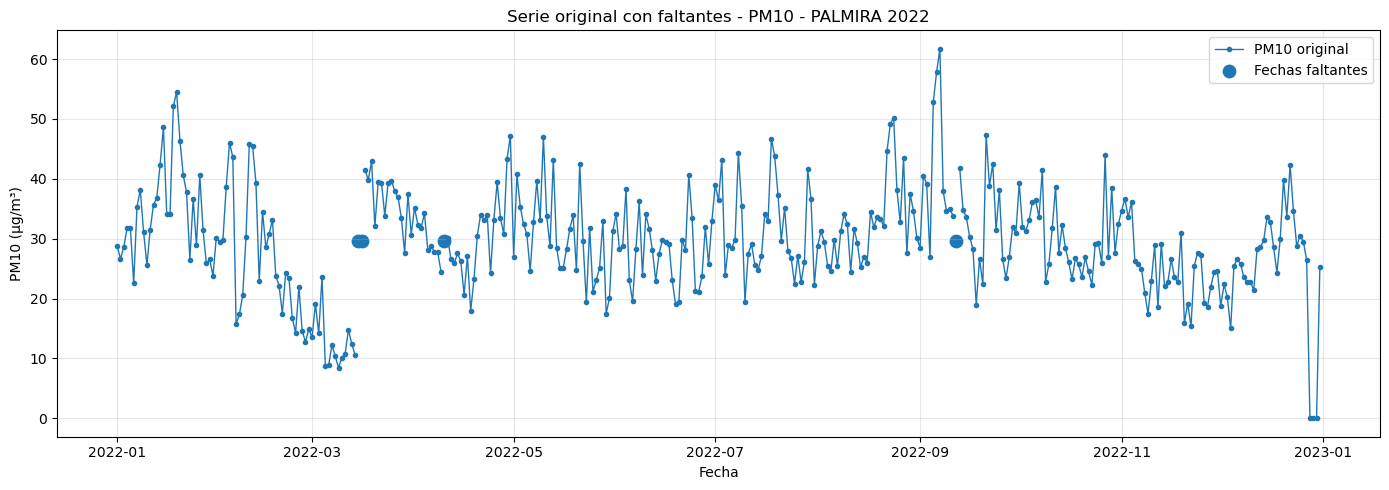

Gráfica guardada en: salidas_imputacion_RF_PM10_PM25_Palmira_2022\graficas\01_serie_original_faltantes_PM10.png


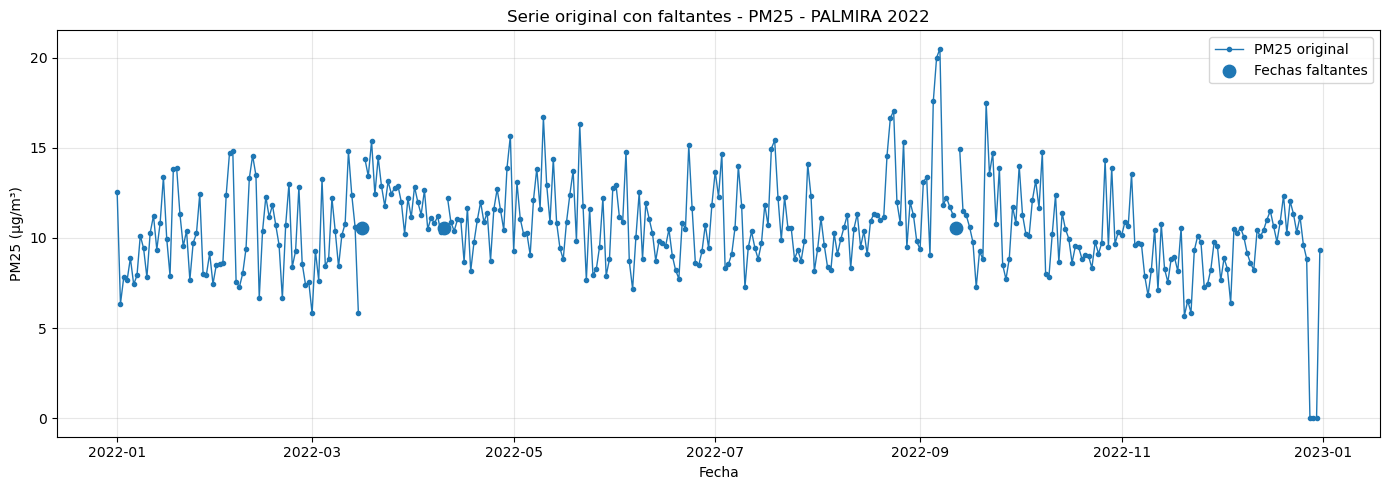

Gráfica guardada en: salidas_imputacion_RF_PM10_PM25_Palmira_2022\graficas\01_serie_original_faltantes_PM25.png


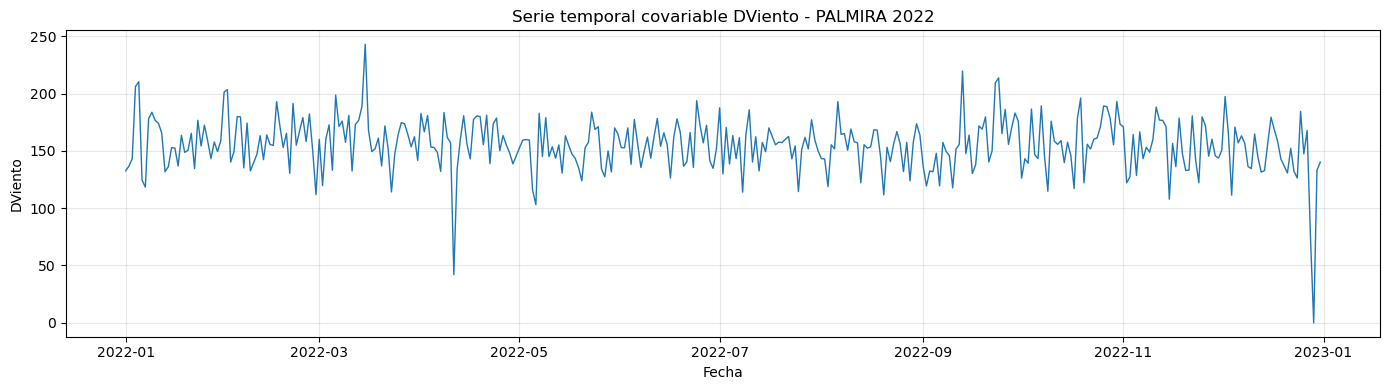

Gráfica guardada en: salidas_imputacion_RF_PM10_PM25_Palmira_2022\graficas\02_serie_covariable_DViento.png


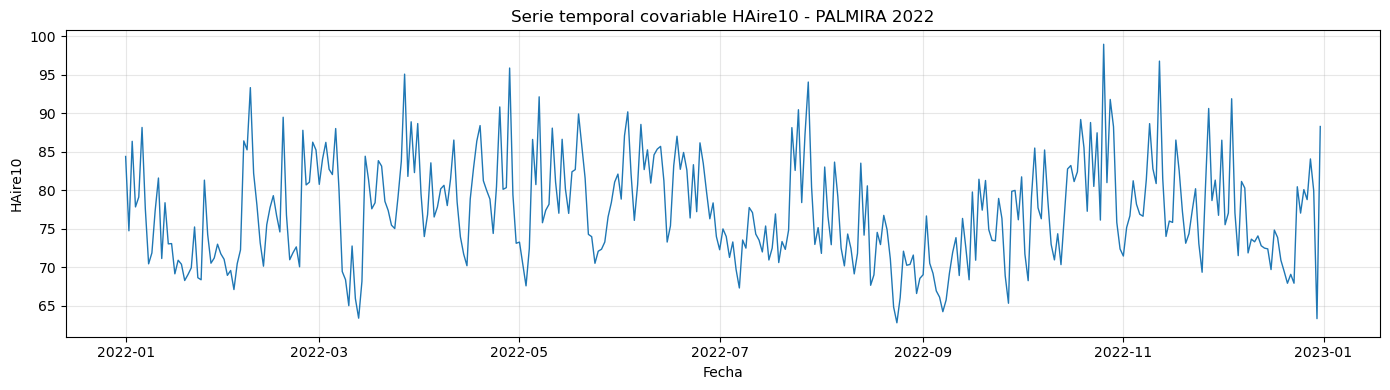

Gráfica guardada en: salidas_imputacion_RF_PM10_PM25_Palmira_2022\graficas\02_serie_covariable_HAire10.png


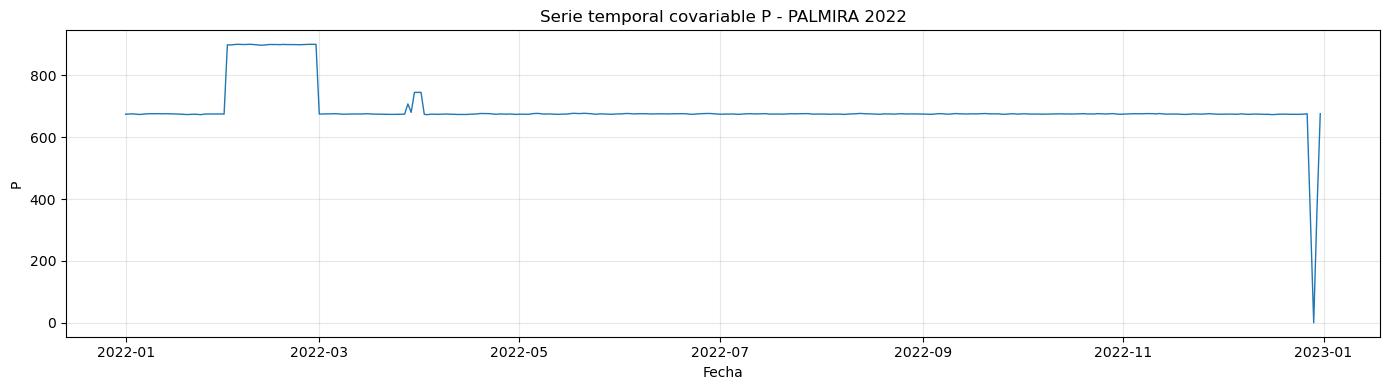

Gráfica guardada en: salidas_imputacion_RF_PM10_PM25_Palmira_2022\graficas\02_serie_covariable_P.png


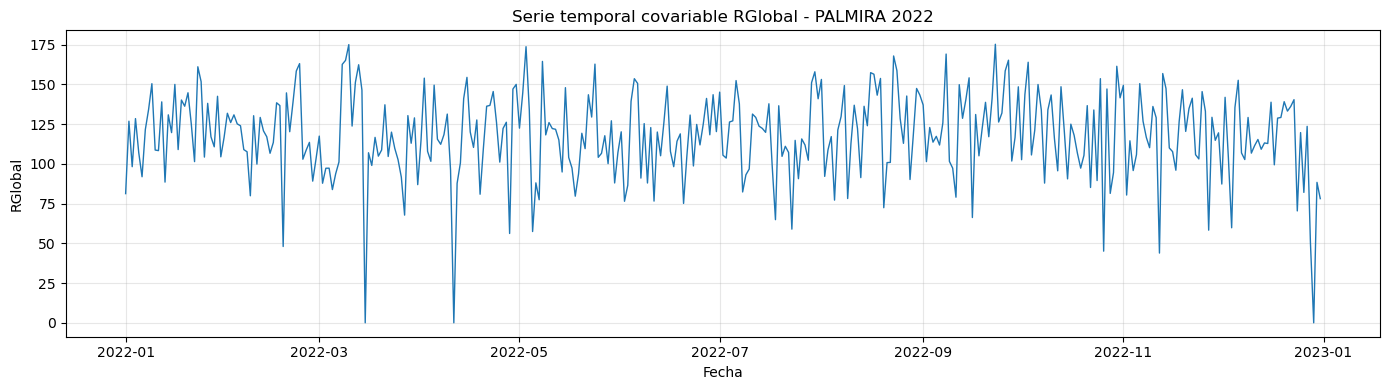

Gráfica guardada en: salidas_imputacion_RF_PM10_PM25_Palmira_2022\graficas\02_serie_covariable_RGlobal.png


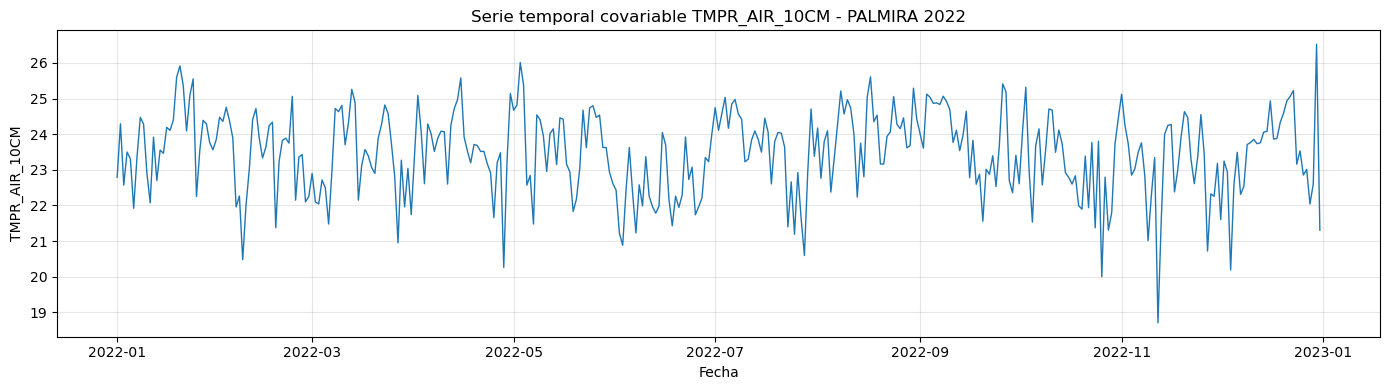

Gráfica guardada en: salidas_imputacion_RF_PM10_PM25_Palmira_2022\graficas\02_serie_covariable_TMPR_AIR_10CM.png


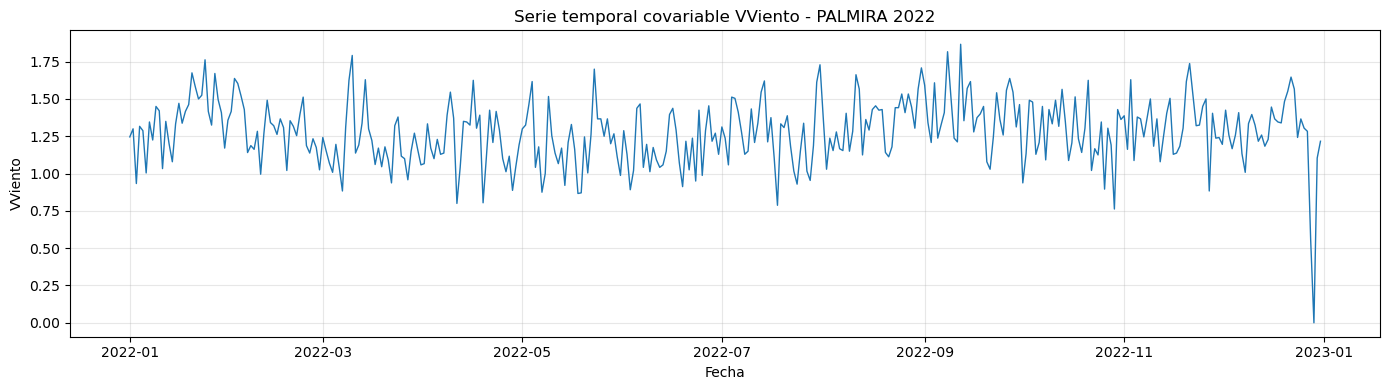

Gráfica guardada en: salidas_imputacion_RF_PM10_PM25_Palmira_2022\graficas\02_serie_covariable_VViento.png


In [51]:
# ==========================================
# 9. GRÁFICAS DE SERIES ORIGINALES Y COVARIABLES
# ==========================================

for target in ["PM10", "PM25"]:
    plt.figure(figsize=(14, 5))
    plt.plot(base["Fecha inicial"], base[target], marker="o", markersize=3, linewidth=1, label=f"{target} original")
    faltantes = base[base[target].isna()]
    if len(faltantes) > 0:
        plt.scatter(faltantes["Fecha inicial"], [base[target].mean()] * len(faltantes), s=80, label="Fechas faltantes")
    plt.title(f"Serie original con faltantes - {target} - PALMIRA 2022")
    plt.xlabel("Fecha")
    plt.ylabel(f"{target} (µg/m³)")
    plt.grid(True, alpha=0.3)
    plt.legend()
    guardar_mostrar_figura(f"01_serie_original_faltantes_{target}.png")

for variable in covariables:
    plt.figure(figsize=(14, 4))
    plt.plot(base["Fecha inicial"], base[variable], linewidth=1)
    plt.title(f"Serie temporal covariable {variable} - PALMIRA 2022")
    plt.xlabel("Fecha")
    plt.ylabel(variable)
    plt.grid(True, alpha=0.3)
    guardar_mostrar_figura(f"02_serie_covariable_{variable}.png")

In [52]:
# ==========================================
# 10. INGENIERÍA DE VARIABLES PARA RANDOM FOREST
# ==========================================

def crear_features(df, covariables):
    d = df.copy()

    # Variables calendario
    d["dia_anio"] = d["Fecha inicial"].dt.dayofyear
    d["mes"] = d["Fecha inicial"].dt.month
    d["dia_mes"] = d["Fecha inicial"].dt.day
    d["dia_semana"] = d["Fecha inicial"].dt.dayofweek
    d["semana_anio"] = d["Fecha inicial"].dt.isocalendar().week.astype(int)

    # Codificación cíclica para capturar patrones anuales
    d["dia_anio_sin"] = np.sin(2 * np.pi * d["dia_anio"] / 365.0)
    d["dia_anio_cos"] = np.cos(2 * np.pi * d["dia_anio"] / 365.0)

    # Rezagos y medias móviles de covariables meteorológicas
    # No se usan rezagos del contaminante para evitar usar información imputada de la misma variable.
    for c in covariables:
        for lag in [1, 2, 3, 7]:
            d[f"{c}_lag{lag}"] = d[c].shift(lag)

        d[f"{c}_media3"] = d[c].rolling(3, min_periods=1).mean()
        d[f"{c}_media7"] = d[c].rolling(7, min_periods=1).mean()

    feature_cols = (
        covariables
        + ["dia_anio", "mes", "dia_mes", "dia_semana", "semana_anio", "dia_anio_sin", "dia_anio_cos"]
        + [col for col in d.columns if any(col.startswith(f"{c}_") for c in covariables)]
    )

    # Se rellenan rezagos iniciales de covariables para no perder días al inicio del año.
    d[feature_cols] = d[feature_cols].bfill().ffill()

    return d, feature_cols


base_modelo, feature_cols = crear_features(base, covariables)

display(Markdown("## Variables predictoras usadas por Random Forest"))
display(pd.DataFrame({"Feature": feature_cols}))

print("Total de variables predictoras:", len(feature_cols))
print("Faltantes en matriz de predictores:", base_modelo[feature_cols].isna().sum().sum())

pd.DataFrame({"Feature": feature_cols}).to_csv(TABLAS / "10_variables_predictoras_RF.csv", index=False, encoding="utf-8-sig")

## Variables predictoras usadas por Random Forest

,Feature
0,DViento
1,HAire10
2,P
3,RGlobal
4,TMPR_AIR_10CM
5,VViento
6,dia_anio
7,mes
8,dia_mes
9,dia_semana


Total de variables predictoras: 49
Faltantes en matriz de predictores: 0


In [53]:
# ==========================================
# 11. ENTRENAMIENTO Y VALIDACIÓN DEL RANDOM FOREST
# ==========================================

def entrenar_validar_imputar_rf(df, target, feature_cols, random_state=42, val_frac=0.20):
    data = df.copy()

    observado = data[target].notna()
    indices_observados = data.index[observado].to_numpy()

    # Validación por ocultamiento aleatorio del 20% de los datos observados.
    # Se entrena con el 80% observado y se valida contra el 20% oculto.
    idx_train, idx_val = train_test_split(
        indices_observados,
        test_size=val_frac,
        random_state=random_state,
        shuffle=True
    )

    X_train = data.loc[idx_train, feature_cols]
    y_train = data.loc[idx_train, target]

    X_val = data.loc[idx_val, feature_cols]
    y_val = data.loc[idx_val, target]

    modelo_validacion = RandomForestRegressor(
        n_estimators=600,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=2,
        max_features="sqrt",
        random_state=random_state,
        n_jobs=-1,
        bootstrap=True,
        oob_score=True
    )

    modelo_validacion.fit(X_train, y_train)

    pred_train = modelo_validacion.predict(X_train)
    pred_val = modelo_validacion.predict(X_val)

    metricas = {
        "Variable": target,
        "Registros_observados": int(observado.sum()),
        "Registros_faltantes_a_imputar": int((~observado).sum()),
        "Entrenamiento_validacion": int(len(idx_train)),
        "Validacion_oculta": int(len(idx_val)),
        "MAE_entrenamiento": mean_absolute_error(y_train, pred_train),
        "RMSE_entrenamiento": np.sqrt(mean_squared_error(y_train, pred_train)),
        "R2_entrenamiento": r2_score(y_train, pred_train),
        "MAE_validacion": mean_absolute_error(y_val, pred_val),
        "RMSE_validacion": np.sqrt(mean_squared_error(y_val, pred_val)),
        "MAPE_validacion_%": mape_sin_ceros(y_val, pred_val),
        "sMAPE_validacion_%": smape(y_val, pred_val),
        "R2_validacion": r2_score(y_val, pred_val),
        "OOB_score": modelo_validacion.oob_score_
    }

    tabla_validacion = data.loc[idx_val, ["Estacion", "Fecha inicial", target]].copy()
    tabla_validacion[f"{target}_pred_RF_validacion"] = pred_val
    tabla_validacion["Error"] = tabla_validacion[target] - tabla_validacion[f"{target}_pred_RF_validacion"]
    tabla_validacion["Error_abs"] = tabla_validacion["Error"].abs()
    tabla_validacion = tabla_validacion.sort_values("Fecha inicial")

    # Modelo final entrenado con todos los datos reales disponibles
    modelo_final = RandomForestRegressor(
        n_estimators=600,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=2,
        max_features="sqrt",
        random_state=random_state,
        n_jobs=-1,
        bootstrap=True,
        oob_score=True
    )

    modelo_final.fit(data.loc[observado, feature_cols], data.loc[observado, target])

    pred_todos = modelo_final.predict(data[feature_cols])

    salida = data[["Estacion", "Fecha inicial", target]].copy()
    salida[f"{target}_pred_RF"] = pred_todos
    salida[f"{target}_RF_final"] = salida[target]
    salida.loc[salida[target].isna(), f"{target}_RF_final"] = salida.loc[salida[target].isna(), f"{target}_pred_RF"]
    salida[f"Fue_faltante_{target}"] = salida[target].isna()
    salida[f"Fuente_valor_{target}"] = np.where(salida[f"Fue_faltante_{target}"], "Imputado_RF", "Original")

    importancia = pd.DataFrame({
        "Variable_objetivo": target,
        "Feature": feature_cols,
        "Importancia": modelo_final.feature_importances_
    }).sort_values("Importancia", ascending=False)

    return metricas, tabla_validacion, salida, importancia, modelo_validacion, modelo_final


resultados = {}
for target in ["PM10", "PM25"]:
    display(Markdown(f"## Entrenando Random Forest para {target}"))
    resultados[target] = entrenar_validar_imputar_rf(base_modelo, target, feature_cols)

metricas = pd.DataFrame([resultados["PM10"][0], resultados["PM25"][0]])
display(Markdown("## Métricas de entrenamiento y validación"))
display(metricas)

metricas.to_csv(TABLAS / "11_metricas_validacion_RF_imputacion.csv", index=False, encoding="utf-8-sig")

## Entrenando Random Forest para PM10

## Entrenando Random Forest para PM25

## Métricas de entrenamiento y validación

,Variable,Registros_observados,Registros_faltantes_a_imputar,Entrenamiento_validacion,Validacion_oculta,MAE_entrenamiento,RMSE_entrenamiento,R2_entrenamiento,MAE_validacion,RMSE_validacion,MAPE_validacion_%,sMAPE_validacion_%,R2_validacion,OOB_score
0,PM10,361,4,288,73,2.336137,3.245401,0.864696,5.553131,7.551362,20.046597,22.687748,0.301277,0.337936
1,PM25,362,3,289,73,0.715052,0.988256,0.842348,1.665923,2.229280,16.190150,17.676480,0.220887,0.228275


In [54]:
# ==========================================
# 12. TABLAS DE VALIDACIÓN DEL MODELO
# ==========================================

for target in ["PM10", "PM25"]:
    tabla_validacion = resultados[target][1]
    display(Markdown(f"## Validación con datos ocultos - {target}"))
    display(tabla_validacion.head(20))

    tabla_validacion.to_csv(TABLAS / f"12_validacion_oculta_{target}_RF.csv", index=False, encoding="utf-8-sig")

## Validación con datos ocultos - PM10

,Estacion,Fecha inicial,PM10,PM10_pred_RF_validacion,Error,Error_abs
3,PALMIRA,2022-01-04,31.741667,32.184181,-0.442515,0.442515
5,PALMIRA,2022-01-06,22.550000,29.831884,-7.281884,7.281884
9,PALMIRA,2022-01-10,25.600000,31.245096,-5.645096,5.645096
15,PALMIRA,2022-01-16,34.141667,33.700811,0.440856,0.440856
22,PALMIRA,2022-01-23,26.475000,37.010276,-10.535276,10.535276
25,PALMIRA,2022-01-26,40.550000,31.587541,8.962459,8.962459
30,PALMIRA,2022-01-31,30.183333,29.871545,0.311789,0.311789
33,PALMIRA,2022-02-03,38.562500,36.629597,1.932903,1.932903
39,PALMIRA,2022-02-09,30.345833,24.996208,5.349625,5.349625
42,PALMIRA,2022-02-12,39.337500,29.621958,9.715542,9.715542


## Validación con datos ocultos - PM25

,Estacion,Fecha inicial,PM25,PM25_pred_RF_validacion,Error,Error_abs
3,PALMIRA,2022-01-04,7.645833,10.025321,-2.379488,2.379488
5,PALMIRA,2022-01-06,7.425000,9.764211,-2.339211,2.339211
9,PALMIRA,2022-01-10,7.816667,10.091540,-2.274873,2.274873
15,PALMIRA,2022-01-16,9.958333,9.844429,0.113905,0.113905
22,PALMIRA,2022-01-23,7.670833,10.605865,-2.935031,2.935031
25,PALMIRA,2022-01-26,12.437500,10.576280,1.861220,1.861220
30,PALMIRA,2022-01-31,8.504167,9.983969,-1.479802,1.479802
33,PALMIRA,2022-02-03,12.387500,11.775406,0.612094,0.612094
39,PALMIRA,2022-02-09,9.412500,9.352106,0.060394,0.060394
42,PALMIRA,2022-02-12,13.470833,9.949945,3.520888,3.520888


In [55]:
# ==========================================
# 13. CONSTRUCCIÓN DE BASE FINAL IMPUTADA
# ==========================================

# IMPORTANTE:
# La base original ya tiene las columnas Fue_faltante_PM10 y Fue_faltante_PM25.
# Por eso, al unir las salidas del modelo NO volvemos a traer esas columnas,
# porque pandas crearía columnas con sufijos (_x, _y) y luego aparecería el KeyError.

base_final = base.copy()

# Asegurar que las columnas de control existan
if "Fue_faltante_PM10" not in base_final.columns:
    base_final["Fue_faltante_PM10"] = base_final["PM10"].isna()

if "Fue_faltante_PM25" not in base_final.columns:
    base_final["Fue_faltante_PM25"] = base_final["PM25"].isna()

for target in ["PM10", "PM25"]:
    salida = resultados[target][2][[
        "Estacion",
        "Fecha inicial",
        f"{target}_pred_RF",
        f"{target}_RF_final",
        f"Fuente_valor_{target}"
    ]].copy()

    base_final = base_final.merge(
        salida,
        on=["Estacion", "Fecha inicial"],
        how="left"
    )

columnas_finales = [
    "Estacion", "Fecha inicial",
    "DViento", "HAire10", "P", "RGlobal", "TMPR_AIR_10CM", "VViento",
    "PM10", "PM10_pred_RF", "PM10_RF_final", "Fue_faltante_PM10", "Fuente_valor_PM10",
    "PM25", "PM25_pred_RF", "PM25_RF_final", "Fue_faltante_PM25", "Fuente_valor_PM25"
]

# Validación preventiva: si alguna columna falta, se muestra exactamente cuál es.
columnas_faltantes = [col for col in columnas_finales if col not in base_final.columns]
if columnas_faltantes:
    print("Columnas disponibles en base_final:")
    print(base_final.columns.tolist())
    raise KeyError(f"Faltan estas columnas en base_final: {columnas_faltantes}")

base_final = base_final[columnas_finales].copy()

display(Markdown("## Base final imputada"))
display(base_final.head())
display(base_final.tail())

base_final.to_csv(SALIDAS / "base_PM10_PM25_Palmira_2022_imputada_RF.csv", index=False, encoding="utf-8-sig")



## Base final imputada

,Estacion,Fecha inicial,DViento,HAire10,P,RGlobal,TMPR_AIR_10CM,VViento,PM10,PM10_pred_RF,PM10_RF_final,Fue_faltante_PM10,Fuente_valor_PM10,PM25,PM25_pred_RF,PM25_RF_final,Fue_faltante_PM25,Fuente_valor_PM25
0,PALMIRA,2022-01-01,132.583333,84.366667,674.733333,81.258333,22.791667,1.245833,28.779167,26.933595,28.779167,False,Original,12.520833,10.410859,12.520833,False,Original
1,PALMIRA,2022-01-02,136.625000,74.720833,675.304167,126.820833,24.291667,1.300000,26.645833,27.535371,26.645833,False,Original,6.350000,7.893786,6.350000,False,Original
2,PALMIRA,2022-01-03,143.083333,86.337500,675.820833,98.195833,22.570833,0.933333,28.575000,28.109398,28.575000,False,Original,7.825000,8.604940,7.825000,False,Original
3,PALMIRA,2022-01-04,206.166667,77.820833,674.791667,128.458333,23.500000,1.316667,31.741667,31.457885,31.741667,False,Original,7.645833,8.465312,7.645833,False,Original
4,PALMIRA,2022-01-05,210.291667,79.095833,673.908333,106.945833,23.308333,1.287500,31.750000,31.794663,31.750000,False,Original,8.879167,9.210181,8.879167,False,Original


,Estacion,Fecha inicial,DViento,HAire10,P,RGlobal,TMPR_AIR_10CM,VViento,PM10,PM10_pred_RF,PM10_RF_final,Fue_faltante_PM10,Fuente_valor_PM10,PM25,PM25_pred_RF,PM25_RF_final,Fue_faltante_PM25,Fuente_valor_PM25
360,PALMIRA,2022-12-27,167.791667,78.766667,676.062500,123.587500,23.012500,1.283333,26.400000,26.195391,26.400000,False,Original,8.85,8.895697,8.85,False,Original
361,PALMIRA,2022-12-28,76.166667,84.050000,338.354167,50.545833,22.041667,0.558333,0.000000,10.582613,0.000000,False,Original,0.00,4.345081,0.00,False,Original
362,PALMIRA,2022-12-29,0.000000,79.933778,0.000000,0.000000,22.598753,0.000000,0.000000,6.988326,0.000000,False,Original,0.00,2.727762,0.00,False,Original
363,PALMIRA,2022-12-30,133.208333,63.315385,365.312500,88.341667,26.523077,1.104167,0.000000,11.468576,0.000000,False,Original,0.00,3.741502,0.00,False,Original
364,PALMIRA,2022-12-31,140.125000,88.258333,676.395833,78.108333,21.308333,1.216667,25.283333,18.248331,25.283333,False,Original,9.35,6.615720,9.35,False,Original


In [56]:
# ==========================================
# 14. ESTADÍSTICOS ANTES Y DESPUÉS DE IMPUTAR
# ==========================================

estadisticos_antes_despues = pd.DataFrame([
    {"Variable": "PM10", "Momento": "Antes de imputar", **estadisticos(base_final["PM10"])},
    {"Variable": "PM10", "Momento": "Después de imputar RF", **estadisticos(base_final["PM10_RF_final"])},
    {"Variable": "PM25", "Momento": "Antes de imputar", **estadisticos(base_final["PM25"])},
    {"Variable": "PM25", "Momento": "Después de imputar RF", **estadisticos(base_final["PM25_RF_final"])},
])

display(estadisticos_antes_despues)

estadisticos_antes_despues.to_csv(
    TABLAS / "13_estadisticos_antes_despues_RF_imputacion.csv",
    index=False,
    encoding="utf-8-sig"
)

,Variable,Momento,n,faltantes,media,mediana,desv_std,min,q25,q75,max
0,PM10,Antes de imputar,361,4,29.589909,29.066667,8.879208,0.0,24.508333,34.166667,61.704167
1,PM10,Después de imputar RF,365,0,29.598363,29.066667,8.835715,0.0,24.516667,34.166667,61.704167
2,PM25,Antes de imputar,362,3,10.535139,10.383333,2.501837,0.0,8.872917,11.898958,20.487500
3,PM25,Después de imputar RF,365,0,10.539206,10.387500,2.492774,0.0,8.879167,11.916667,20.487500


In [57]:
# ==========================================
# 15. FECHAS Y VALORES IMPUTADOS
# ==========================================

fechas_imputadas = pd.concat([
    base_final.loc[
        base_final["Fue_faltante_PM10"],
        ["Estacion", "Fecha inicial", "PM10", "PM10_pred_RF", "PM10_RF_final"]
    ].rename(columns={"PM10": "Valor_original", "PM10_pred_RF": "Prediccion_RF", "PM10_RF_final": "Valor_final_imputado"}).assign(Variable="PM10"),

    base_final.loc[
        base_final["Fue_faltante_PM25"],
        ["Estacion", "Fecha inicial", "PM25", "PM25_pred_RF", "PM25_RF_final"]
    ].rename(columns={"PM25": "Valor_original", "PM25_pred_RF": "Prediccion_RF", "PM25_RF_final": "Valor_final_imputado"}).assign(Variable="PM25")
], ignore_index=True)

fechas_imputadas = fechas_imputadas[[
    "Variable", "Estacion", "Fecha inicial", "Valor_original", "Prediccion_RF", "Valor_final_imputado"
]]

display(Markdown("## Valores imputados por Random Forest"))
display(fechas_imputadas)

fechas_imputadas.to_csv(TABLAS / "14_fechas_y_valores_imputados_RF.csv", index=False, encoding="utf-8-sig")

## Valores imputados por Random Forest

,Variable,Estacion,Fecha inicial,Valor_original,Prediccion_RF,Valor_final_imputado
0,PM10,PALMIRA,2022-03-15,NaN,27.968586,27.968586
1,PM10,PALMIRA,2022-03-16,NaN,30.026693,30.026693
2,PM10,PALMIRA,2022-04-10,NaN,28.333428,28.333428
3,PM10,PALMIRA,2022-09-12,NaN,35.116374,35.116374
4,PM25,PALMIRA,2022-03-16,NaN,10.748485,10.748485
5,PM25,PALMIRA,2022-04-10,NaN,10.318418,10.318418
6,PM25,PALMIRA,2022-09-12,NaN,12.022939,12.022939


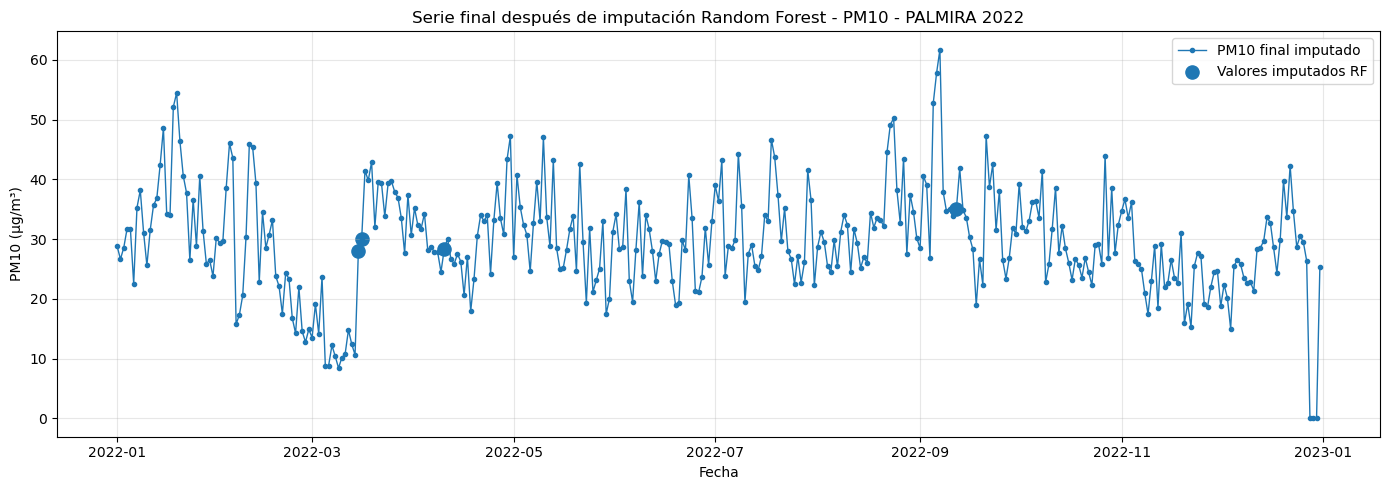

Gráfica guardada en: salidas_imputacion_RF_PM10_PM25_Palmira_2022\graficas\03_serie_final_imputada_RF_PM10.png


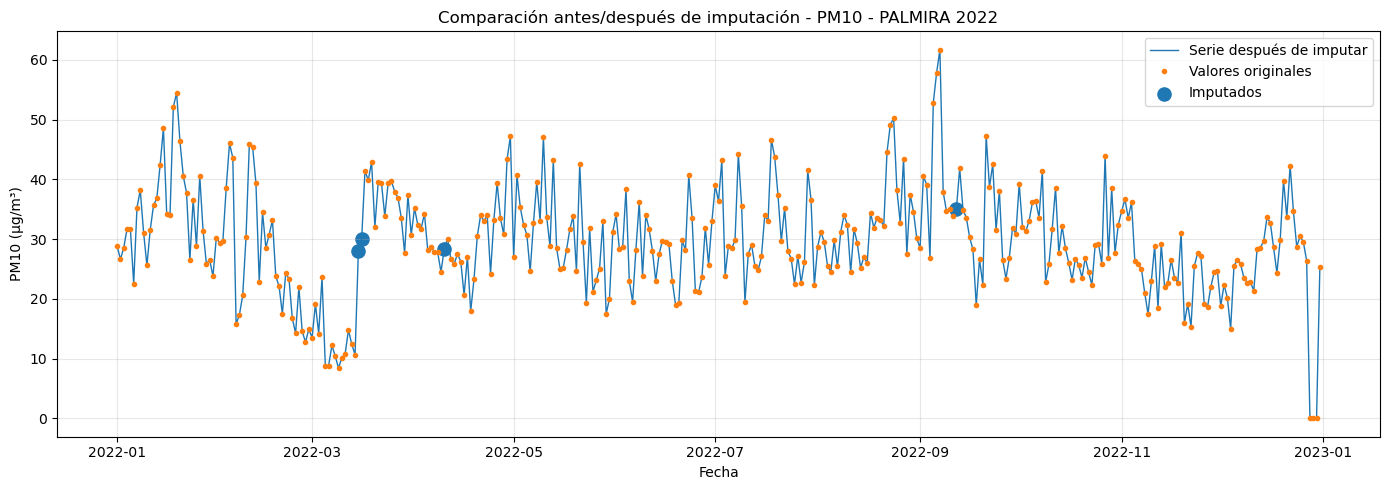

Gráfica guardada en: salidas_imputacion_RF_PM10_PM25_Palmira_2022\graficas\04_comparacion_antes_despues_PM10.png


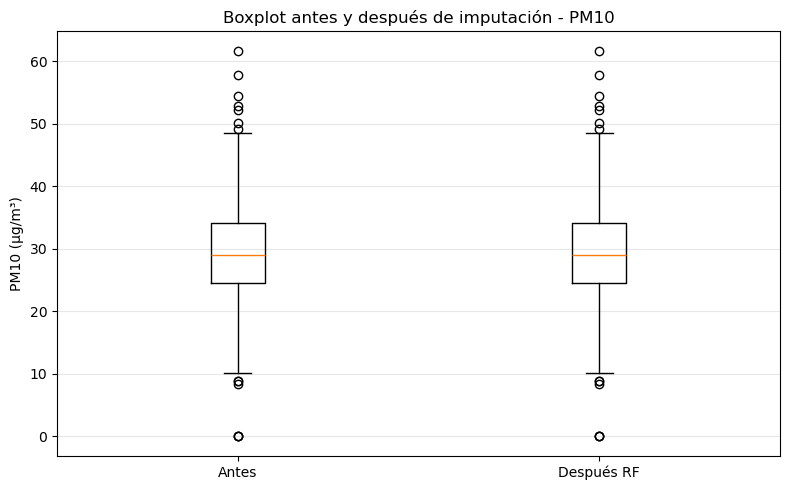

Gráfica guardada en: salidas_imputacion_RF_PM10_PM25_Palmira_2022\graficas\05_boxplot_antes_despues_PM10.png


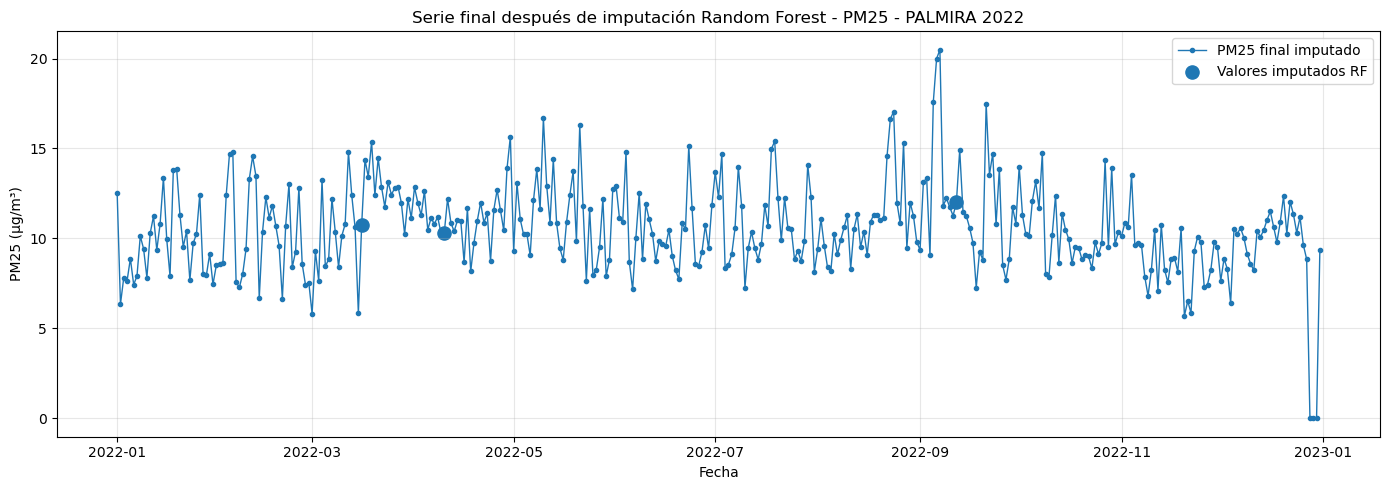

Gráfica guardada en: salidas_imputacion_RF_PM10_PM25_Palmira_2022\graficas\03_serie_final_imputada_RF_PM25.png


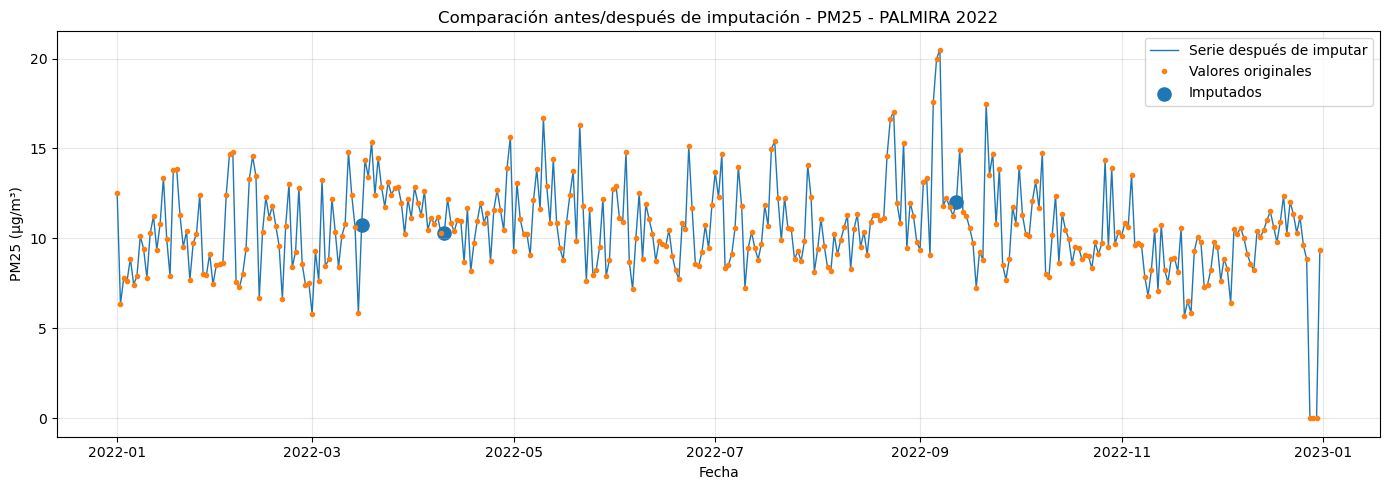

Gráfica guardada en: salidas_imputacion_RF_PM10_PM25_Palmira_2022\graficas\04_comparacion_antes_despues_PM25.png


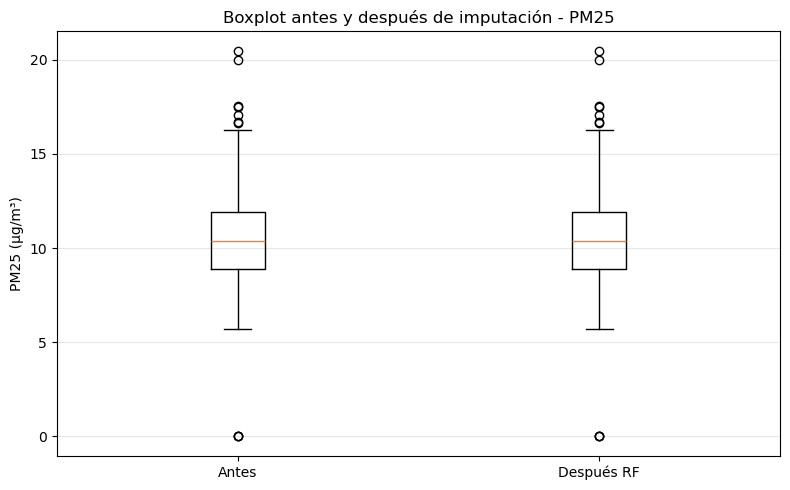

Gráfica guardada en: salidas_imputacion_RF_PM10_PM25_Palmira_2022\graficas\05_boxplot_antes_despues_PM25.png


In [58]:
# ==========================================
# 16. GRÁFICAS DESPUÉS DE IMPUTAR
# ==========================================

for target in ["PM10", "PM25"]:
    plt.figure(figsize=(14, 5))
    plt.plot(base_final["Fecha inicial"], base_final[f"{target}_RF_final"], marker="o", markersize=3, linewidth=1, label=f"{target} final imputado")
    imputados = base_final[base_final[f"Fue_faltante_{target}"]]
    if len(imputados) > 0:
        plt.scatter(imputados["Fecha inicial"], imputados[f"{target}_RF_final"], s=90, label="Valores imputados RF")
    plt.title(f"Serie final después de imputación Random Forest - {target} - PALMIRA 2022")
    plt.xlabel("Fecha")
    plt.ylabel(f"{target} (µg/m³)")
    plt.grid(True, alpha=0.3)
    plt.legend()
    guardar_mostrar_figura(f"03_serie_final_imputada_RF_{target}.png")

    plt.figure(figsize=(14, 5))
    plt.plot(base_final["Fecha inicial"], base_final[f"{target}_RF_final"], linewidth=1, label="Serie después de imputar")
    plt.plot(base_final["Fecha inicial"], base_final[target], linestyle="None", marker="o", markersize=3, label="Valores originales")
    if len(imputados) > 0:
        plt.scatter(imputados["Fecha inicial"], imputados[f"{target}_RF_final"], s=90, label="Imputados")
    plt.title(f"Comparación antes/después de imputación - {target} - PALMIRA 2022")
    plt.xlabel("Fecha")
    plt.ylabel(f"{target} (µg/m³)")
    plt.grid(True, alpha=0.3)
    plt.legend()
    guardar_mostrar_figura(f"04_comparacion_antes_despues_{target}.png")

    plt.figure(figsize=(8, 5))
    plt.boxplot([base_final[target].dropna(), base_final[f"{target}_RF_final"].dropna()], labels=["Antes", "Después RF"])
    plt.title(f"Boxplot antes y después de imputación - {target}")
    plt.ylabel(f"{target} (µg/m³)")
    plt.grid(True, axis="y", alpha=0.3)
    guardar_mostrar_figura(f"05_boxplot_antes_despues_{target}.png")

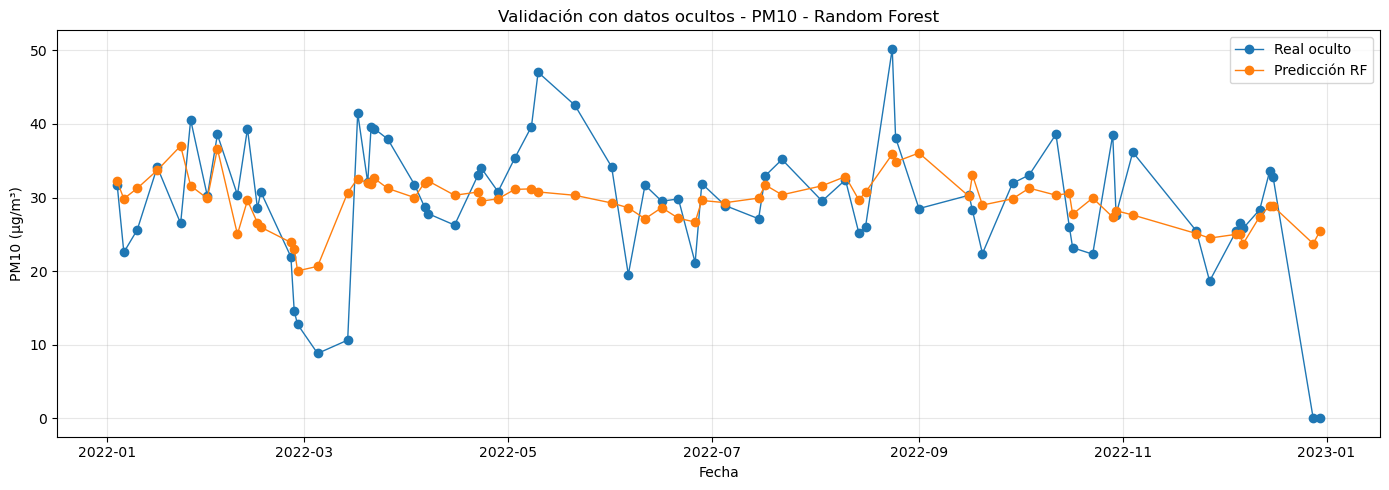

Gráfica guardada en: salidas_imputacion_RF_PM10_PM25_Palmira_2022\graficas\06_validacion_oculta_RF_PM10.png


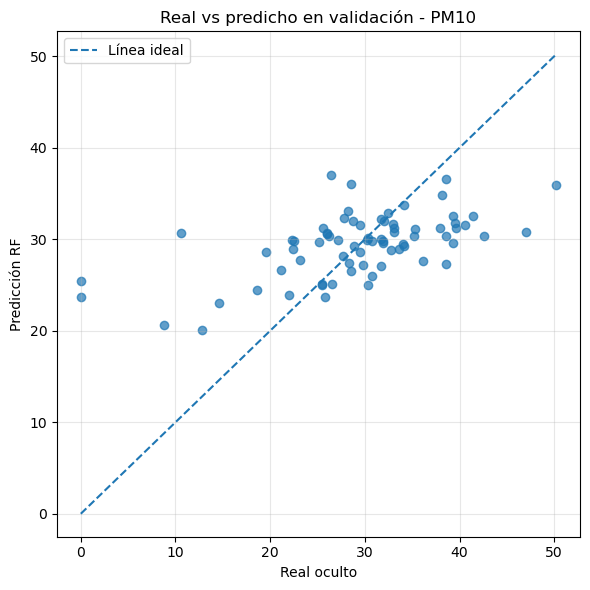

Gráfica guardada en: salidas_imputacion_RF_PM10_PM25_Palmira_2022\graficas\07_real_vs_predicho_validacion_PM10.png


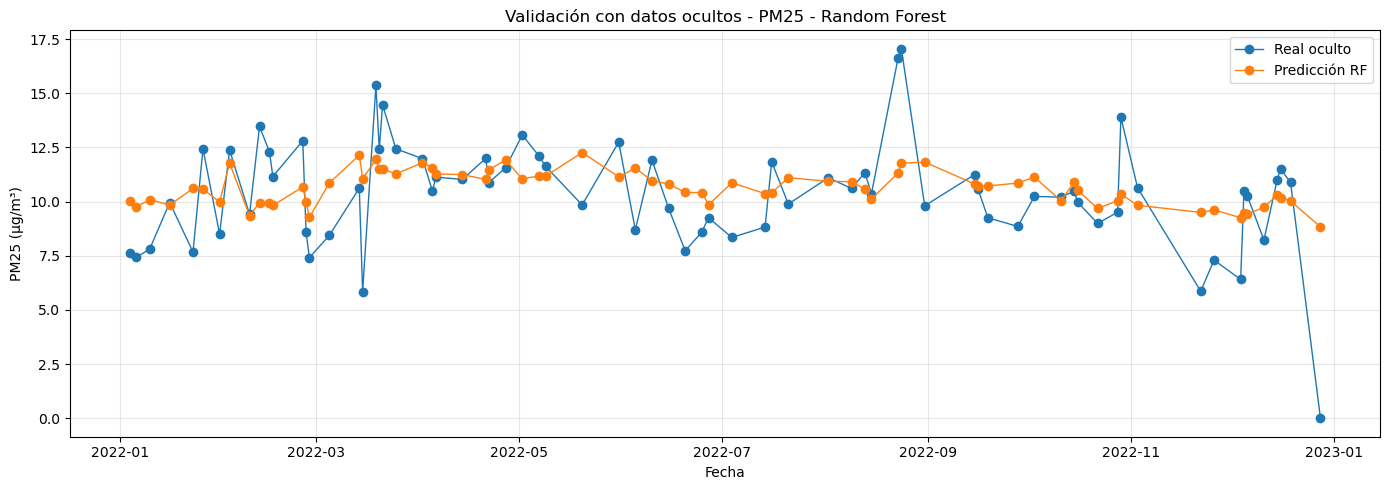

Gráfica guardada en: salidas_imputacion_RF_PM10_PM25_Palmira_2022\graficas\06_validacion_oculta_RF_PM25.png


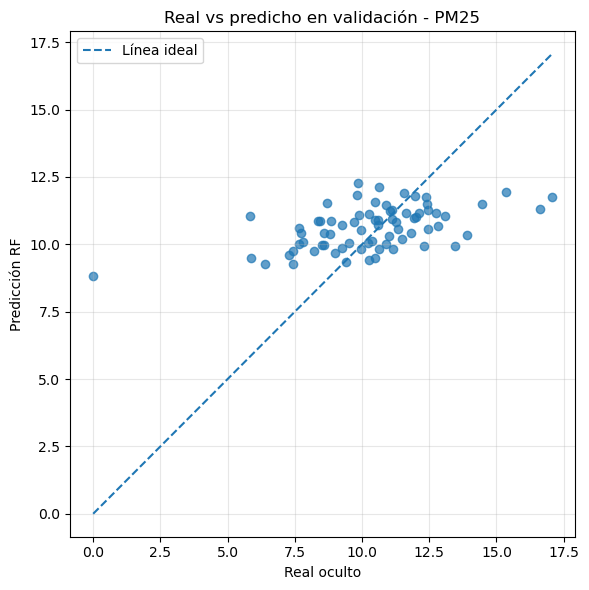

Gráfica guardada en: salidas_imputacion_RF_PM10_PM25_Palmira_2022\graficas\07_real_vs_predicho_validacion_PM25.png


In [59]:
# ==========================================
# 17. GRÁFICAS DE VALIDACIÓN DEL MODELO
# ==========================================

for target in ["PM10", "PM25"]:
    tabla_validacion = resultados[target][1].sort_values("Fecha inicial")

    plt.figure(figsize=(14, 5))
    plt.plot(tabla_validacion["Fecha inicial"], tabla_validacion[target], marker="o", linewidth=1, label="Real oculto")
    plt.plot(tabla_validacion["Fecha inicial"], tabla_validacion[f"{target}_pred_RF_validacion"], marker="o", linewidth=1, label="Predicción RF")
    plt.title(f"Validación con datos ocultos - {target} - Random Forest")
    plt.xlabel("Fecha")
    plt.ylabel(f"{target} (µg/m³)")
    plt.grid(True, alpha=0.3)
    plt.legend()
    guardar_mostrar_figura(f"06_validacion_oculta_RF_{target}.png")

    plt.figure(figsize=(6, 6))
    plt.scatter(tabla_validacion[target], tabla_validacion[f"{target}_pred_RF_validacion"], alpha=0.7)
    minv = min(tabla_validacion[target].min(), tabla_validacion[f"{target}_pred_RF_validacion"].min())
    maxv = max(tabla_validacion[target].max(), tabla_validacion[f"{target}_pred_RF_validacion"].max())
    plt.plot([minv, maxv], [minv, maxv], linestyle="--", label="Línea ideal")
    plt.title(f"Real vs predicho en validación - {target}")
    plt.xlabel("Real oculto")
    plt.ylabel("Predicción RF")
    plt.grid(True, alpha=0.3)
    plt.legend()
    guardar_mostrar_figura(f"07_real_vs_predicho_validacion_{target}.png")

## Importancia de variables Random Forest

,Variable_objetivo,Feature,Importancia
0,PM10,HAire10_media7,0.047589
1,PM10,dia_anio,0.046555
2,PM10,dia_anio_cos,0.044083
3,PM10,HAire10,0.042388
4,PM10,TMPR_AIR_10CM,0.039888
5,PM10,HAire10_media3,0.032620
6,PM10,semana_anio,0.030945
7,PM10,dia_anio_sin,0.030507
8,PM10,RGlobal_media3,0.027531
9,PM10,VViento,0.027087


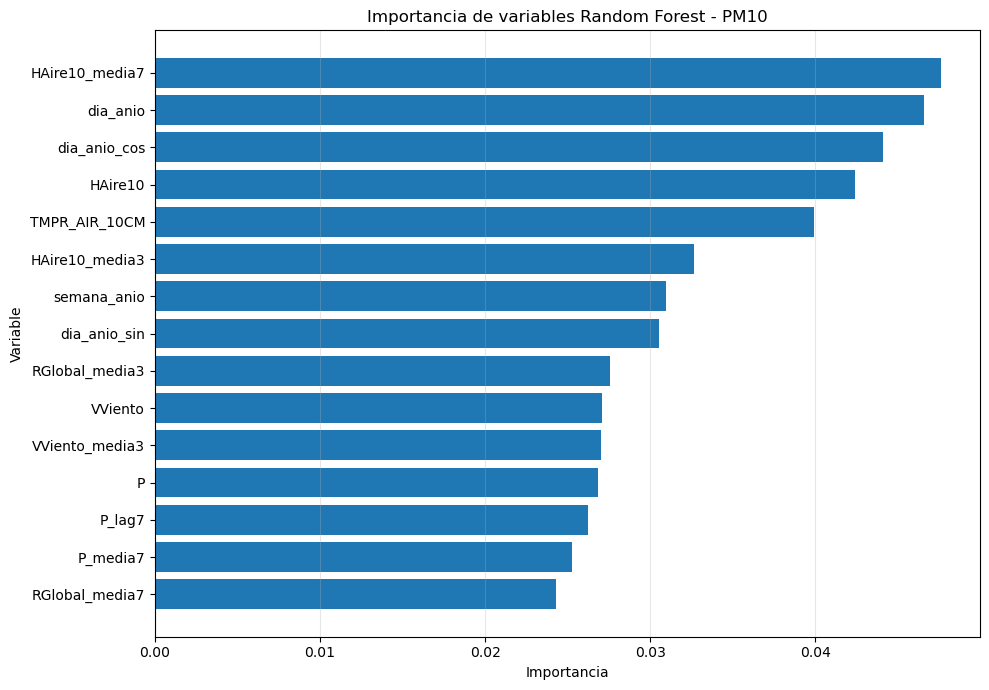

Gráfica guardada en: salidas_imputacion_RF_PM10_PM25_Palmira_2022\graficas\08_importancia_variables_RF_PM10.png


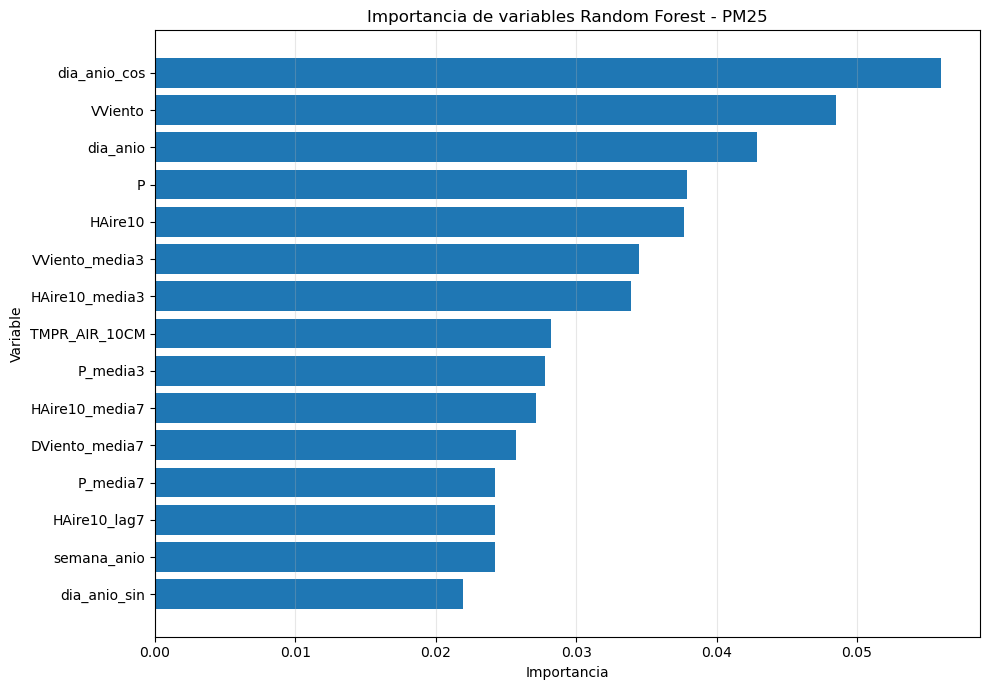

Gráfica guardada en: salidas_imputacion_RF_PM10_PM25_Palmira_2022\graficas\08_importancia_variables_RF_PM25.png


In [60]:
# ==========================================
# 18. IMPORTANCIA DE VARIABLES
# ==========================================

importancia_total = pd.concat(
    [resultados["PM10"][3], resultados["PM25"][3]],
    ignore_index=True
)

display(Markdown("## Importancia de variables Random Forest"))
display(importancia_total.head(30))

importancia_total.to_csv(TABLAS / "15_importancia_variables_RF_imputacion.csv", index=False, encoding="utf-8-sig")

for target in ["PM10", "PM25"]:
    importancia = importancia_total[importancia_total["Variable_objetivo"].eq(target)].head(15)
    importancia = importancia.sort_values("Importancia")

    plt.figure(figsize=(10, 7))
    plt.barh(importancia["Feature"], importancia["Importancia"])
    plt.title(f"Importancia de variables Random Forest - {target}")
    plt.xlabel("Importancia")
    plt.ylabel("Variable")
    plt.grid(True, axis="x", alpha=0.3)
    guardar_mostrar_figura(f"08_importancia_variables_RF_{target}.png")

,PM10_RF_final,PM25_RF_final,DViento,HAire10,P,RGlobal,TMPR_AIR_10CM,VViento
PM10_RF_final,1.000000,0.815726,0.061982,-0.261639,0.100377,0.157813,0.270902,0.079215
PM25_RF_final,0.815726,1.000000,0.115025,-0.168775,0.192944,0.180185,0.178199,-0.045125
DViento,0.061982,0.115025,1.000000,-0.045761,0.265734,0.336318,0.036856,0.251028
HAire10,-0.261639,-0.168775,-0.045761,1.000000,0.022753,-0.612163,-0.893330,-0.616662
P,0.100377,0.192944,0.265734,0.022753,1.000000,0.153426,-0.023816,0.213165
RGlobal,0.157813,0.180185,0.336318,-0.612163,0.153426,1.000000,0.573307,0.605884
TMPR_AIR_10CM,0.270902,0.178199,0.036856,-0.893330,-0.023816,0.573307,1.000000,0.545571
VViento,0.079215,-0.045125,0.251028,-0.616662,0.213165,0.605884,0.545571,1.000000


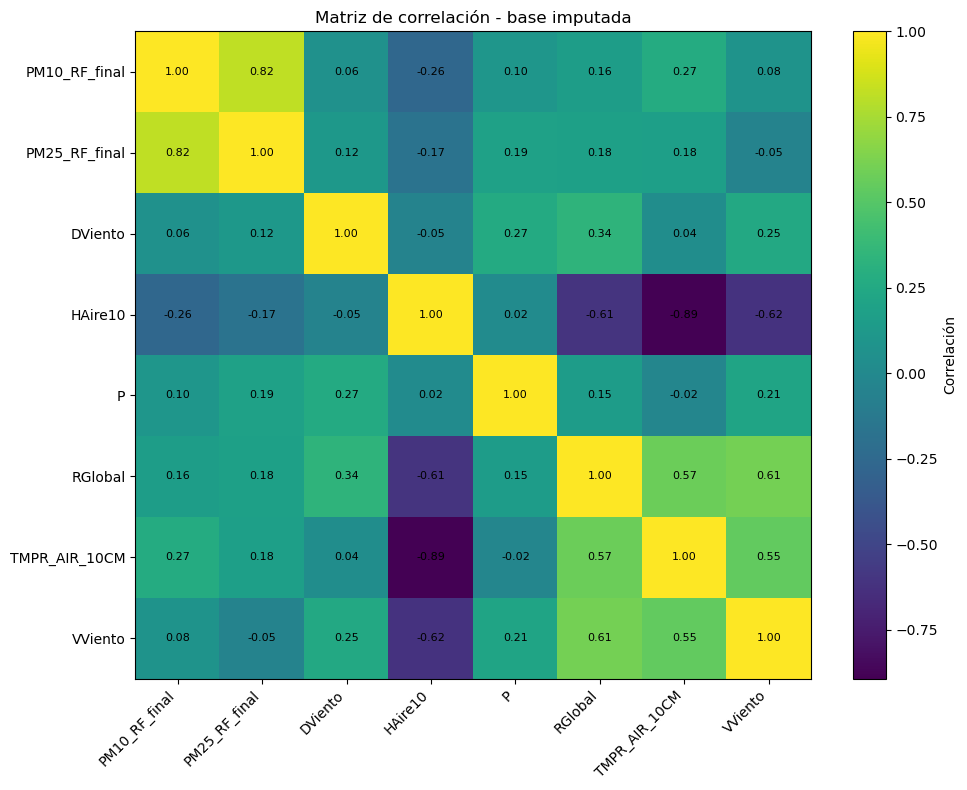

Gráfica guardada en: salidas_imputacion_RF_PM10_PM25_Palmira_2022\graficas\09_matriz_correlacion_base_imputada.png


In [61]:
# ==========================================
# 19. MATRIZ DE CORRELACIÓN FINAL
# ==========================================

columnas_corr = ["PM10_RF_final", "PM25_RF_final"] + covariables
corr = base_final[columnas_corr].corr()

display(corr)

corr.to_csv(TABLAS / "16_matriz_correlacion_base_imputada.csv", encoding="utf-8-sig")

plt.figure(figsize=(10, 8))
plt.imshow(corr, aspect="auto")
plt.colorbar(label="Correlación")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.index)), corr.index)

for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

plt.title("Matriz de correlación - base imputada")
guardar_mostrar_figura("09_matriz_correlacion_base_imputada.png")

In [62]:
# ==========================================
# 20. RESUMEN FINAL PARA TESIS
# ==========================================

display(Markdown("## Resumen final de la imputación"))

resumen_final = pd.DataFrame({
    "Variable": ["PM10", "PM25"],
    "Faltantes_antes": [
        base_final["PM10"].isna().sum(),
        base_final["PM25"].isna().sum()
    ],
    "Faltantes_despues": [
        base_final["PM10_RF_final"].isna().sum(),
        base_final["PM25_RF_final"].isna().sum()
    ],
    "Registros_finales": [len(base_final), len(base_final)]
})

display(resumen_final)
display(metricas[[
    "Variable",
    "MAE_validacion",
    "RMSE_validacion",
    "MAPE_validacion_%",
    "sMAPE_validacion_%",
    "R2_validacion",
    "OOB_score"
]])

resumen_final.to_csv(TABLAS / "17_resumen_final_imputacion.csv", index=False, encoding="utf-8-sig")

print("Proceso finalizado.")
print(f"Base final imputada: {SALIDAS / 'base_PM10_PM25_Palmira_2022_imputada_RF.csv'}")
print(f"Tablas: {TABLAS}")
print(f"Gráficas: {GRAFICAS}")

## Resumen final de la imputación

,Variable,Faltantes_antes,Faltantes_despues,Registros_finales
0,PM10,4,0,365
1,PM25,3,0,365


,Variable,MAE_validacion,RMSE_validacion,MAPE_validacion_%,sMAPE_validacion_%,R2_validacion,OOB_score
0,PM10,5.553131,7.551362,20.046597,22.687748,0.301277,0.337936
1,PM25,1.665923,2.229280,16.190150,17.676480,0.220887,0.228275


Proceso finalizado.
Base final imputada: salidas_imputacion_RF_PM10_PM25_Palmira_2022\base_PM10_PM25_Palmira_2022_imputada_RF.csv
Tablas: salidas_imputacion_RF_PM10_PM25_Palmira_2022\tablas
Gráficas: salidas_imputacion_RF_PM10_PM25_Palmira_2022\graficas


## Texto base para el documento de tesis

La imputación de los valores faltantes de PM10 y PM2.5 se realizó mediante un modelo Random Forest Regressor, utilizando como variables explicativas covariables meteorológicas y características temporales derivadas de la fecha. Las covariables consideradas fueron dirección del viento, humedad relativa, precipitación, radiación global, temperatura del aire a 10 cm y velocidad del viento. Adicionalmente, se incorporaron rezagos y medias móviles de las covariables, junto con variables calendario como mes, día de la semana y día del año.

Para evaluar la capacidad del modelo de imputación, se aplicó una validación por ocultamiento de datos observados. En este procedimiento, una proporción de registros reales fue retirada temporalmente del entrenamiento y posteriormente estimada por el modelo. Las predicciones obtenidas fueron comparadas contra los valores reales ocultos mediante métricas como MAE, RMSE, MAPE, sMAPE y R². Finalmente, el modelo fue entrenado con todos los registros observados disponibles y se utilizó para imputar las fechas faltantes identificadas en las series de PM10 y PM2.5.

In [68]:
# ============================================================
# EXPORTAR DATASETS FINALES COMPLETOS
# INCLUYENDO VALORES OBSERVADOS + VALORES IMPUTADOS
# FORMATO FINAL SIMPLE
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

# Carpeta donde está corriendo el notebook
CARPETA_ACTUAL = Path.cwd()

print("Los archivos se exportarán en:")
print(CARPETA_ACTUAL)

# Verificar que exista base_final
try:
    base_final.head()
except NameError:
    raise NameError(
        "No existe la variable base_final. "
        "Ejecuta primero la celda donde se construye la base final imputada."
    )

# Copia de trabajo
base_exportar = base_final.copy()

# Asegurar formato de fecha
base_exportar["Fecha inicial"] = pd.to_datetime(
    base_exportar["Fecha inicial"],
    errors="coerce"
)

# Si no existe Fecha final, se crea vacía
if "Fecha final" not in base_exportar.columns:
    base_exportar["Fecha final"] = np.nan

# ============================================================
# DATASET FINAL COMPLETO PM10
# USA PM10_RF_final = observado + imputado
# ============================================================

dataset_PM10_final = base_exportar[[
    "Estacion",
    "Fecha inicial",
    "Fecha final",
    "PM10_RF_final"
]].copy()

dataset_PM10_final = dataset_PM10_final.rename(columns={
    "PM10_RF_final": "PM10"
})

dataset_PM10_final = dataset_PM10_final.sort_values(
    ["Estacion", "Fecha inicial"]
).reset_index(drop=True)

ruta_pm10 = CARPETA_ACTUAL / "PM10_dataset_completo_final.csv"

dataset_PM10_final.to_csv(
    ruta_pm10,
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# DATASET FINAL COMPLETO PM2.5
# USA PM25_RF_final = observado + imputado
# ============================================================

dataset_PM25_final = base_exportar[[
    "Estacion",
    "Fecha inicial",
    "Fecha final",
    "PM25_RF_final"
]].copy()

dataset_PM25_final = dataset_PM25_final.rename(columns={
    "PM25_RF_final": "PM25"
})

dataset_PM25_final = dataset_PM25_final.sort_values(
    ["Estacion", "Fecha inicial"]
).reset_index(drop=True)

ruta_pm25 = CARPETA_ACTUAL / "PM25_dataset_completo_final.csv"

dataset_PM25_final.to_csv(
    ruta_pm25,
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# VERIFICACIÓN FINAL
# ============================================================

print("\nDatasets finales exportados correctamente:")
print(ruta_pm10)
print(ruta_pm25)

print("\nResumen PM10 final:")
print("Filas:", len(dataset_PM10_final))
print("Faltantes PM10:", dataset_PM10_final["PM10"].isna().sum())
display(dataset_PM10_final.head())
display(dataset_PM10_final.tail())

print("\nResumen PM2.5 final:")
print("Filas:", len(dataset_PM25_final))
print("Faltantes PM25:", dataset_PM25_final["PM25"].isna().sum())
display(dataset_PM25_final.head())
display(dataset_PM25_final.tail())

Los archivos se exportarán en:
C:\Users\santi\Cali_Real

Datasets finales exportados correctamente:
C:\Users\santi\Cali_Real\PM10_dataset_completo_final.csv
C:\Users\santi\Cali_Real\PM25_dataset_completo_final.csv

Resumen PM10 final:
Filas: 365
Faltantes PM10: 0


,Estacion,Fecha inicial,Fecha final,PM10
0,PALMIRA,2022-01-01,NaN,28.779167
1,PALMIRA,2022-01-02,NaN,26.645833
2,PALMIRA,2022-01-03,NaN,28.575000
3,PALMIRA,2022-01-04,NaN,31.741667
4,PALMIRA,2022-01-05,NaN,31.750000


,Estacion,Fecha inicial,Fecha final,PM10
360,PALMIRA,2022-12-27,NaN,26.400000
361,PALMIRA,2022-12-28,NaN,0.000000
362,PALMIRA,2022-12-29,NaN,0.000000
363,PALMIRA,2022-12-30,NaN,0.000000
364,PALMIRA,2022-12-31,NaN,25.283333



Resumen PM2.5 final:
Filas: 365
Faltantes PM25: 0


,Estacion,Fecha inicial,Fecha final,PM25
0,PALMIRA,2022-01-01,NaN,12.520833
1,PALMIRA,2022-01-02,NaN,6.350000
2,PALMIRA,2022-01-03,NaN,7.825000
3,PALMIRA,2022-01-04,NaN,7.645833
4,PALMIRA,2022-01-05,NaN,8.879167


,Estacion,Fecha inicial,Fecha final,PM25
360,PALMIRA,2022-12-27,NaN,8.85
361,PALMIRA,2022-12-28,NaN,0.00
362,PALMIRA,2022-12-29,NaN,0.00
363,PALMIRA,2022-12-30,NaN,0.00
364,PALMIRA,2022-12-31,NaN,9.35
